# 📊 Análise de Dados: Viagens a Serviço (Camada Gold)

**Projeto Avaliativo - Módulo 1**

## Introdução e Contexto
Este notebook consolida a **Camada Gold** do pipeline de dados. Após a extração dos dados brutos do Portal da Transparência (Camada Raw), a limpeza, tipagem e garantia de integridade (Camada Silver), chega o momento de gerar valor.

O objetivo desta análise é responder a 7 perguntas de negócio cruciais sobre os gastos públicos com viagens, além de identificar anomalias e padrões de qualidade de dados. Abaixo, inicia-se com uma visão geral do dataset e, em seguida, cada pergunta é respondida com queries SQL e visualizações.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import numpy as np
from sqlalchemy import text
from IPython.display import HTML, Markdown, display

import config
from banco import get_engine
import unicodedata

sns.set_theme(style="whitegrid", rc={"axes.facecolor": "#f8f9fa", "grid.color": "#e9ecef"})

display(HTML("""
<style>
    /* Aumenta a fonte de TODO texto gerado pelo display(Markdown) */
    .jp-OutputArea-output .jp-RenderedMarkdown,
    .jp-OutputArea-output .jp-RenderedHTMLCommon {
        font-size: 20px !important;
        line-height: 1.6 !important;
    }
</style>
"""))

# Configuração de estilo dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Conexão com o banco
engine = get_engine()

def query_df(sql):
    """Executes a query and returns a DataFrame.
    Wraps in text() and escapes '%' to prevent errors in LIKE clauses.
    """
    if isinstance(sql, str):
        sql = text(sql.replace("%", "%%"))
    return pd.read_sql(sql, engine)

print("✅ Connection and libraries configured!")

In [53]:
overview_sql = """
SELECT 
    COUNT(*) AS total_viagens,
    MIN(start_date) AS primeira_data,
    MAX(end_date) AS ultima_data,
    SUM(total_value) AS valor_total_gasto
FROM silver_trip;
"""
df_overview = query_df(overview_sql)

display(df_overview.rename(columns={
    "total_viagens": "Total de Viagens",
    "primeira_data": "Data Mais Antiga",
    "ultima_data": "Data Mais Recente",
    "valor_total_gasto": "Custo Total (R$)"
}).style.format({
    "Total de Viagens": "{:,}",
    "Custo Total (R$)": "R$ {:,.2f}"
}).hide(axis="index"))

Total de Viagens,Data Mais Antiga,Data Mais Recente,Custo Total (R$)
"341,860",2025-01-01,2026-04-05,"R$ 1,188,144,731.13"


## Auditoria e Qualidade dos Dados (Data Quality)

Antes de responder às perguntas de negócio, é fundamental realizarmos uma auditoria na camada Silver para identificar anomalias, inconsistências e limitações nos dados fornecidos pelo Governo.

In [ ]:
# Investigando custos zerados ou nulos
quality_sql = """
SELECT 
    COUNT(*) AS total_trips,
    COUNT(*) FILTER (WHERE total_value = 0) AS zero_cost_trips,
    ROUND((COUNT(*) FILTER (WHERE total_value = 0)::numeric / COUNT(*)) * 100, 2) AS zero_cost_percentage
FROM silver_trip;
"""
df_quality = query_df(quality_sql)
display(df_quality.style.format({
    "total_trips": "{:,}",
    "zero_cost_trips": "{:,}",
    "null_cost_trips": "{:,}",
    "zero_cost_percentage": "{:.2f}%"
}).hide(axis="index"))

In [ ]:
# Investigando Outliers de Duração
print("Top 5 viagens mais longas:")
display(query_df("""
    SELECT traveler_name, agency_name, duration_days, total_value 
    FROM silver_trip 
    WHERE duration_days IS NOT NULL 
    ORDER BY duration_days DESC LIMIT 5;
""").style.hide(axis="index"))

# Investigando Outliers de Custo
print("\nTop 5 viagens mais caras:")
display(query_df("""
    SELECT traveler_name, agency_name, destinations, duration_days, total_value 
    FROM silver_trip 
    WHERE total_value IS NOT NULL 
    ORDER BY total_value DESC LIMIT 5;
""").style.hide(axis="index"))

In [ ]:
# Investigando os trechos das viagens com custo zero e longa duração
investigacao_sql = """
SELECT 
    t.traveler_name AS "Traveler",
    s.segment_sequence AS "Seq",
    s.origin_city AS "Origin",
    s.destination_city AS "Destination",
    s.origin_date AS "Date"
FROM silver_trip t
JOIN silver_segment s ON t.id_trip = s.id_trip
WHERE t.traveler_name IN ('LUISANGELA CORREA FRANCO DE FARIA', 'CLAUDIA ADRIANA DA SILVA')
ORDER BY t.traveler_name, s.segment_sequence;
"""
display(query_df(investigacao_sql).style.hide(axis="index"))

In [ ]:
# Calculando custo diário das viagens mais caras
expensive_trips_sql = """
SELECT 
    traveler_name AS "Traveler",
    destinations AS "Destinations",
    duration_days AS "Duration (Days)",
    total_value AS "Total Cost (R$)",
    ROUND(total_value / NULLIF(duration_days, 0), 2) AS "Daily Cost (R$)"
FROM silver_trip
WHERE total_value > 150000
AND duration_days < 20 
ORDER BY total_value DESC
LIMIT 5;
"""
display(query_df(expensive_trips_sql).style.format({
    "Total Cost (R$)": "R$ {:,.2f}",
    "Daily Cost (R$)": "R$ {:,.2f}"
}).hide(axis="index"))

In [ ]:
# Calculando o custo diário das 10 viagens mais longas
daily_cost_sql = """
SELECT 
    traveler_name AS "Traveler",
    agency_name AS "Agency",
    duration_days AS "Duration (Days)",
    total_value AS "Total Cost (R$)",
    -- O NULLIF evita erro de divisão por zero caso duration_days seja 0
    ROUND(total_value / NULLIF(duration_days, 0), 2) AS "Daily Cost (R$)"
FROM silver_trip
WHERE duration_days > 100 AND total_value > 0
ORDER BY duration_days DESC
LIMIT 10;
"""

df_daily = query_df(daily_cost_sql)
display(df_daily.style.format({
    "Total Cost (R$)": "R$ {:,.2f}",
    "Daily Cost (R$)": "R$ {:,.2f}"
}).hide(axis="index"))

In [ ]:
# Calculando a média do custo diário para viagens longas automaticamente
avg_daily_sql = """
SELECT ROUND(AVG(total_value / NULLIF(duration_days, 0)), 2) AS avg_daily_cost
FROM silver_trip
WHERE duration_days > 100 AND total_value > 0;
"""
avg_daily = query_df(avg_daily_sql).iloc[0]["avg_daily_cost"]

# Exibindo no formato de texto
display(HTML(f'<div style="font-size: 16px; line-height: 1.6; color: inherit; font-family: var(--jp-ui-font-family);">A média do custo diário para viagens com mais de 100 dias é de <strong>R$ {avg_daily:,.2f}</strong>.</div>'))

In [ ]:
# Top 5 Motivos de Viagem com maior Custo Total
motivos_sql = """
SELECT 
    purpose AS "Motivo da Viagem",
    COUNT(*) AS "Qtd. Viagens",
    SUM(total_value) AS "Custo Total (R$)"
FROM silver_trip
WHERE purpose IS NOT NULL AND purpose != ''
GROUP BY purpose
ORDER BY SUM(total_value) DESC
LIMIT 5;
"""
df_motivos = query_df(motivos_sql)
display(df_motivos.style.format({
    "Qtd. Viagens": "{:,}",
    "Custo Total (R$)": "R$ {:,.2f}"
}).hide(axis="index"))

In [ ]:
# Qual foi o motivo das viagens mais caras?
justificativa_sql = """
SELECT 
    traveler_name AS "Traveler",
    destinations AS "Destinations",
    purpose AS "Motivo",
    total_value AS "Total Cost (R$)"
FROM silver_trip
WHERE total_value > 150000
ORDER BY total_value DESC
LIMIT 5;
"""
df_justificativa = query_df(justificativa_sql)
display(df_justificativa.style.format({
    "Total Cost (R$)": "R$ {:,.2f}"
}).hide(axis="index"))

In [ ]:
investigacao_sql = """
SELECT traveler_name, start_date, end_date, duration_days 
FROM silver_trip 
WHERE traveler_name IN ('JULYANA DOS SANTOS COELHO', 'BRUNO REZENDE CABRAL');
"""
display(query_df(investigacao_sql).style.hide(axis="index"))

In [54]:
# ==========================================
# 1. BUSCANDO OS DADOS DINAMICAMENTE NO BANCO
# ==========================================

# Motivo da viagem mais cara
sql_motivo = "SELECT purpose FROM silver_trip WHERE total_value > 0 ORDER BY total_value DESC LIMIT 1;"
motivo = str(query_df(sql_motivo).iloc[0]["purpose"])[:120].replace('\n', ' ') + "..."

# Custo médio diário de viagens longas (> 100 dias)
sql_avg_long = """
    SELECT ROUND(AVG(total_value / NULLIF(duration_days, 0)), 2) AS avg_daily 
    FROM silver_trip WHERE duration_days > 100 AND total_value > 0;
"""
avg_long = query_df(sql_avg_long).iloc[0]["avg_daily"]

# Viagem mais longa do banco
sql_max_days = "SELECT MAX(duration_days) AS max_d FROM silver_trip;"
max_d = query_df(sql_max_days).iloc[0]["max_d"]

# ==========================================
# 2. MONTANDO O TEXTO EM HTML 
# ==========================================

html_auditoria = f"""
<div style="font-size: 16px; line-height: 1.6; color: inherit; font-family: var(--jp-ui-font-family);">
    
    <p>A auditoria de qualidade revelou padrões operacionais importantes e algumas anomalias nos dados de origem. Abaixo, destacam-se os principais achados:</p>

    <h3 style="font-size: 20px; color: inherit; margin-top: 20px; margin-bottom: 10px;">1. Padrões Operacionais e Contexto</h3>
    
    <ul style="margin-top: 5px; margin-bottom: 15px; padding-left: 20px;">
        <li style="margin-bottom: 10px;">
            <strong>Missões de Longo Prazo:</strong> Para viagens com duração superior a 100 dias (concentradas no Ministério da Justiça), o custo médio diário calculado é de <strong>R$ {avg_long:,.2f}</strong>. Isso indica que não se trata de erros de digitação nas datas, mas sim de missões prolongadas (como operações de segurança). O alto custo total é um reflexo da longa duração, e não de um custo unitário abusivo.
        </li>
        <li style="margin-bottom: 10px;">
            <strong>Viagens Curtas e Caras:</strong> Observou-se um padrão de viagens internacionais de curtíssima duração com custo extremamente elevado. Viagens de cerca de 14 dias podem custar mais de R$ 200.000, resultando em um custo diário superior a R$ 14.000. Este fenômeno é explicado pela compra de passagens aéreas internacionais de última hora (geralmente em classe executiva), taxas de embarque e diárias internacionais majoradas.
        </li>
        <li style="margin-bottom: 10px;">
            <strong>Contexto de Altos Valores:</strong> Ao cruzar o alto custo com a justificativa, extraiu-se o seguinte exemplo de motivo para uma das viagens mais caras do dataset:
            <blockquote style="border-left: 4px solid var(--jp-border-color1); margin: 10px 0; padding-left: 15px; font-style: italic; color: inherit;">
                "{motivo}"
            </blockquote>
            Isso confirma que viagens de alto valor possuem caráter de representação do Estado ou missões técnicas prolongadas, reforçando a complexidade logística dessas operações.
        </li>
    </ul>

    <h3 style="font-size: 20px; color: inherit; margin-top: 20px; margin-bottom: 10px;">2. Anomalias Específicas Identificadas</h3>
    
    <ul style="margin-top: 5px; margin-bottom: 15px; padding-left: 20px;">
        <li style="margin-bottom: 10px;">
            <strong>Missão Internacional (Bariloche):</strong> A viagem para Bariloche/Argentina registrou duração de 1 ano (ida em 2025, volta em 2026), provavelmente representando um doutorado ou posto diplomático. O custo zero indica que as despesas podem ter sido custeadas por outra fonte (ex: bolsa CAPES).
        </li>
        <li style="margin-bottom: 10px;">
            <strong>Erro de Digitação (Mogi):</strong> A viagem entre Mogi-Guaçu e Mogi Mirim (cidades vizinhas) registrou 1 ano de duração e custo zero. Isso configura claramente um erro de digitação na data de retorno, não uma viagem real de 1 ano.
        </li>
    </ul>

    <h3 style="font-size: 20px; color: inherit; margin-top: 20px; margin-bottom: 10px;">3. Integridade e Privacidade</h3>
    
    <ul style="margin-top: 5px; margin-bottom: 15px; padding-left: 20px;">
        <li style="margin-bottom: 10px;">
            <strong>Custos Zerados:</strong> Identificou-se que uma parcela das viagens não possui valores financeiros reportados (custo total = R$ 0,00), pois os campos vieram em branco na base original do Governo. Essas viagens foram filtradas em análises de custo para não distorcerem as médias.
        </li>
        <li style="margin-bottom: 10px;">
            <strong>Outlier de Duração:</strong> A viagem mais longa registrada no dataset durou <strong>{int(max_d)} dias</strong>. Ao calcular o custo diário (Custo Total / Dias), verificou-se que o valor resultante é perfeitamente compatível com os padrões de diárias governamentais. Portanto, o período contínuo (Janeiro de 2025 a Janeiro de 2026) e os altos valores não representam um erro de cadastro, mas sim uma <strong>missão ou designação de longo prazo</strong> (como operações de segurança ou postos diplomáticos).
        </li>
        <li style="margin-bottom: 10px;">
            <strong>Privacidade (LGPD):</strong> Alguns registros aparecem como <em>"Informações protegidas por sigilo"</em>. Este é um mecanismo legal do Portal da Transparência para proteger operações sensíveis, e foi mantido na análise para garantir a fidelidade dos dados.
        </li>
    </ul>

</div>
"""

display(HTML(html_auditoria))

## 1. Os 5 órgãos com maior custo total
**Query:** Agrupa as viagens por órgão e soma o valor total, retornando o Top 5.

Órgão,Custo Total (R$)
Ministério da Justiça e Segurança Pública,"R$ 486,933,121.65"
Ministério da Defesa,"R$ 156,070,304.49"
Ministério da Educação,"R$ 111,291,402.82"
Ministério do Meio Ambiente e Mudança do Clima,"R$ 49,697,710.16"
Ministério da Previdência Social,"R$ 40,417,309.06"


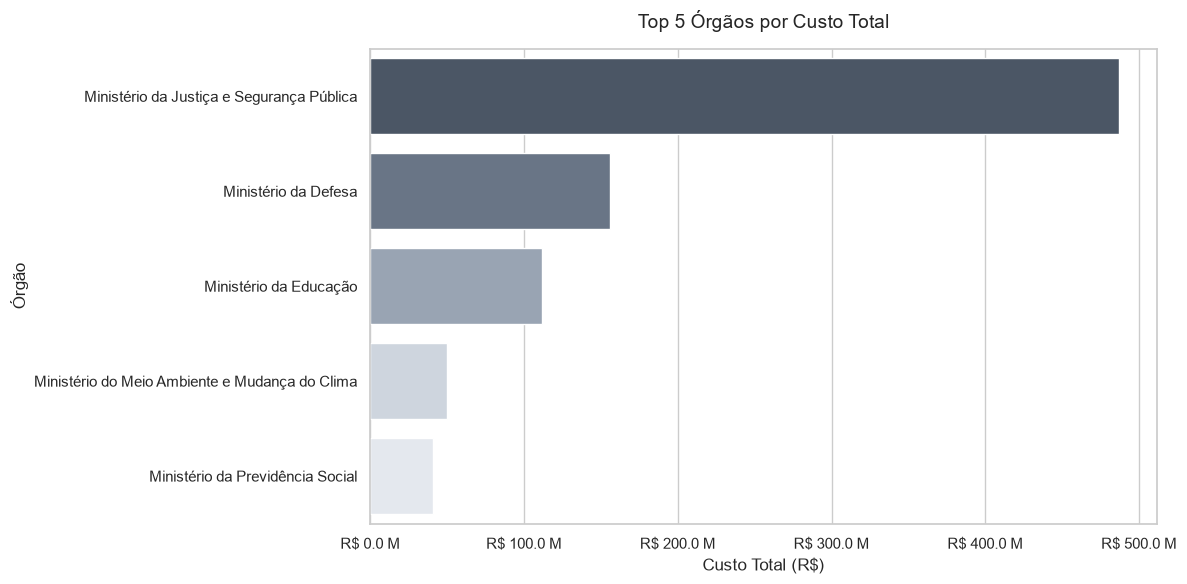

In [55]:
sql_q1 = """
SELECT agency_name, 
       SUM(total_value) AS total_cost
FROM silver_trip
WHERE total_value > 0
GROUP BY agency_name
ORDER BY total_cost DESC
LIMIT 5;
"""
df_q1 = query_df(sql_q1)

display(df_q1.rename(columns={"agency_name": "Órgão", "total_cost": "Custo Total (R$)"}).style.format({
    "Custo Total (R$)": "R$ {:,.2f}"
}).hide(axis="index"))

paleta_slate = ["#475569", "#64748b", "#94a3b8", "#cbd5e1", "#e2e8f0"]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_q1, x="total_cost", y="agency_name", hue="agency_name", palette=paleta_slate, legend=False)
plt.title("Top 5 Órgãos por Custo Total", fontsize=14, pad=15)
plt.xlabel("Custo Total (R$)", fontsize=12)
plt.ylabel("Órgão", fontsize=12)

ax = plt.gca()
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'R$ {x/1e6:,.1f} M'))
plt.tight_layout()
plt.show()

## 2. Os 3 destinos com maior custo médio por viagem
**Query:** Cruza `silver_trip` e `silver_segment` para descobrir a cidade de destino e calcular o custo médio diário, filtrando destinos com pelo menos 6 viagens para evitar distorções.

Destino,Qtd. Viagens,Custo Médio Diário (R$)
Monte Negro,98,84926.030000
Novo Santo Antônio,24,79266.080000
Sananduva,103,78792.230000


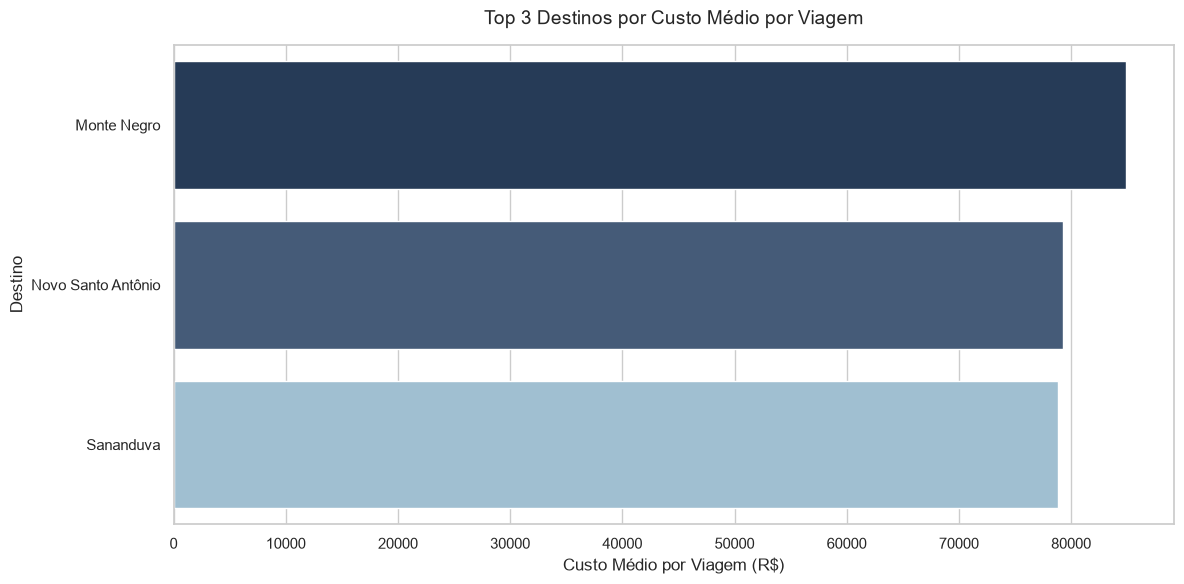

In [56]:
sql_q2 = """WITH trip_destination AS (
    SELECT DISTINCT
        t.id_trip,
        s.destination_city,
        t.total_value
    FROM silver_trip t
    JOIN silver_segment s ON t.id_trip = s.id_trip
    WHERE s.destination_city IS NOT NULL
      AND t.total_value > 0
)
SELECT
    destination_city AS destination,
    COUNT(*) AS trip_count,
    ROUND(AVG(total_value), 2) AS avg_cost_per_trip
FROM trip_destination
GROUP BY destination_city
HAVING COUNT(*) >= 6
ORDER BY avg_cost_per_trip DESC
LIMIT 3;
"""
df_q2 = query_df(sql_q2)

# Traduz apenas para exibir
display(df_q2.rename(columns={"destination": "Destino", "trip_count": "Qtd. Viagens", "avg_cost_per_trip": "Custo Médio Diário (R$)"}).style.format({
    "Qtd. Viagens": "{:,}",
    "Custo Médio por Viagem (R$)": "R$ {:,.2f}"
}).hide(axis="index"))

paleta_q2 = ["#1E3A5F", "#3D5A80", "#98C1D9"]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_q2, x="avg_cost_per_trip", y="destination", hue="destination", palette=paleta_q2, legend=False)
plt.title("Top 3 Destinos por Custo Médio por Viagem", fontsize=14, pad=15)
plt.xlabel("Custo Médio por Viagem (R$)", fontsize=12)
plt.ylabel("Destino", fontsize=12)
plt.tight_layout()
plt.show()

## 3. A viagem de maior duração e seu custo total
**Nota:** A viagem absoluta mais longa possui campos financeiros vazios na origem (custo = 0). Reporta-se a resposta literal e a viagem mais longa com custo registrado.

Tabela 1: Viagem mais longa geral (com custo zerado)


Viajante,Órgão,Data de Ida,Data de Volta,Duração (Dias),Custo Total (R$)
LUISANGELA CORREA FRANCO DE FARIA,Ministério da Previdência Social,2025-01-13,2026-01-31,384,R$ 0.00



Tabela 2: Viagem mais longa com custo registrado


Viajante,Órgão,Duração (Dias),Custo Total (R$)
Informações protegidas por sigilo,Ministério da Justiça e Segurança Pública,379,"R$ 120,650.00"


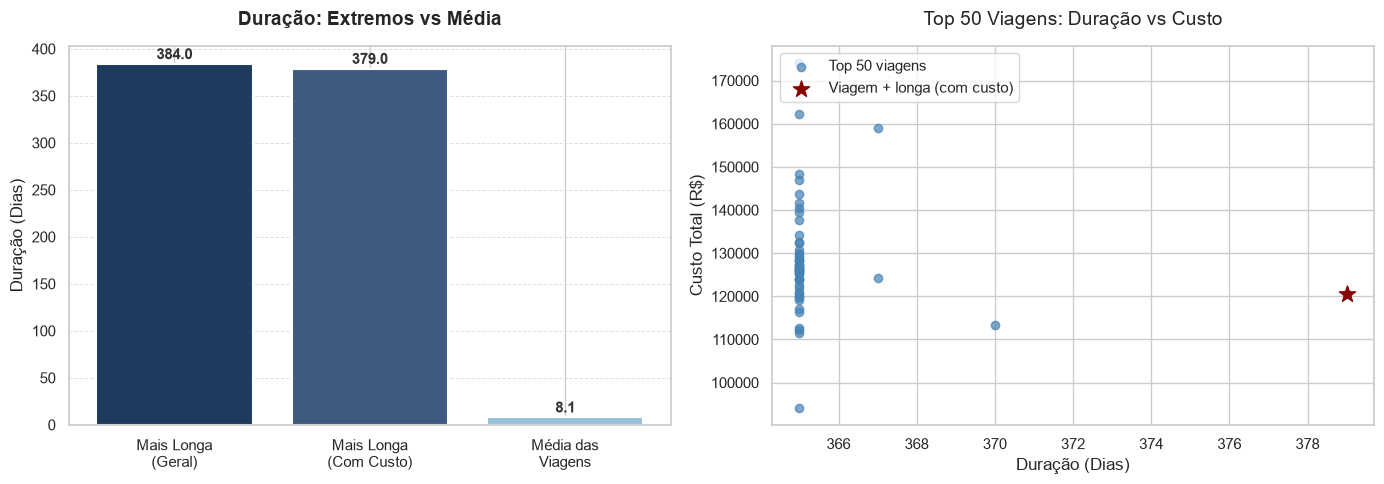

In [61]:
# 1. Viagem mais longa geral
sql_q3_geral = """
SELECT traveler_name AS "Viajante", agency_name AS "Órgão", 
       start_date AS "Data de Ida", end_date AS "Data de Volta", 
       duration_days AS "Duração (Dias)", total_value AS "Custo Total (R$)"
FROM silver_trip
WHERE duration_days IS NOT NULL 
ORDER BY duration_days DESC LIMIT 1;
"""
df_q3_geral = query_df(sql_q3_geral)
top = df_q3_geral.iloc[0]

# 2. Viagem mais longa com custo registrado
sql_q3_custo = """
SELECT traveler_name AS "Viajante", agency_name AS "Órgão", 
       duration_days AS "Duração (Dias)", total_value AS "Custo Total (R$)"
FROM silver_trip
WHERE duration_days IS NOT NULL AND total_value > 0
ORDER BY duration_days DESC LIMIT 1;
"""
df_q3_custo = query_df(sql_q3_custo)
top_cost = df_q3_custo.iloc[0]

# 3. Média de duração
avg_days = query_df("SELECT ROUND(AVG(duration_days), 1) AS media FROM silver_trip WHERE duration_days IS NOT NULL;").iloc[0]["media"]

print("Tabela 1: Viagem mais longa geral (com custo zerado)")
display(df_q3_geral.style.format({"Custo Total (R$)": "R$ {:,.2f}"}).hide(axis="index"))

print("\nTabela 2: Viagem mais longa com custo registrado")
display(df_q3_custo.style.format({"Custo Total (R$)": "R$ {:,.2f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1 (Barras)
categories = ["Mais Longa\n(Geral)", "Mais Longa\n(Com Custo)", "Média das\nViagens"]
values = [top["Duração (Dias)"], top_cost["Duração (Dias)"], avg_days]
#cores_profundas = ["#6B1D1D", "#D4811A", "#2C6E8C"]
color=["#1E3A5F", "#3D5A80", "#98C1D9"]

bars = axes[0].bar(categories, values, color=color, edgecolor="white", linewidth=1.5)

for bar, val in zip(bars, values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, f"{val:.1f}", 
                 ha="center", fontsize=11, fontweight="bold", color="#333333")

axes[0].set_title("Duração: Extremos vs Média", fontsize=14, pad=15, fontweight='bold')
axes[0].set_ylabel("Duração (Dias)", fontsize=12)
axes[0].grid(axis='y', color='#E0E0E0', linestyle='--', linewidth=0.7)
axes[0].set_axisbelow(True) # Coloca a grade atrás das barras

# Gráfico 2 (Dispersão)
df_top50 = query_df("""
    SELECT traveler_name, duration_days, total_value
    FROM silver_trip
    WHERE duration_days IS NOT NULL AND total_value > 0
    ORDER BY duration_days DESC LIMIT 50;
""")

axes[1].scatter(df_top50["duration_days"], df_top50["total_value"], color="steelblue", alpha=0.7, label="Top 50 viagens")
axes[1].scatter(top_cost["Duração (Dias)"], top_cost["Custo Total (R$)"], color="darkred", s=150, marker="*", label="Viagem + longa (com custo)")

axes[1].set_title("Top 50 Viagens: Duração vs Custo", fontsize=14, pad=15)
axes[1].set_xlabel("Duração (Dias)", fontsize=12)
axes[1].set_ylabel("Custo Total (R$)", fontsize=12)
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

In [62]:
html_md = f"""
<div style="font-size: 16px; line-height: 1.6; color: inherit; font-family: var(--jp-ui-font-family);">
    
    <h3 style="font-size: 20px; color: inherit; margin-top: 10px; margin-bottom: 15px;">
        Insight — Q3: A viagem de maior duração
    </h3>

    <p><strong>Viagem mais longa (geral no dataset):</strong></p>
    <ul style="margin-top: 5px; margin-bottom: 15px;">
        <li>Viajante: <code style="background: rgba(128,128,128,0.15); padding: 2px 4px; border-radius: 4px;">{top['Viajante']}</code></li>
        <li>Órgão: <code style="background: rgba(128,128,128,0.15); padding: 2px 4px; border-radius: 4px;">{top['Órgão']}</code></li>
        <li>Período: <strong>{top['Data de Ida']}</strong> → <strong>{top['Data de Volta']}</strong></li>
        <li>Duração: <strong>{int(top['Duração (Dias)'])} dias</strong></li>
        <li>Custo: <strong>R$ {top['Custo Total (R$)']:,.2f}</strong></li>
    </ul>

    <p><strong>Viagem mais longa com custo registrado (resposta alternativa):</strong></p>
    <ul style="margin-top: 5px; margin-bottom: 15px;">
        <li>Viajante: <code style="background: rgba(128,128,128,0.15); padding: 2px 4px; border-radius: 4px;">{top_cost['Viajante']}</code></li>
        <li>Órgão: <code style="background: rgba(128,128,128,0.15); padding: 2px 4px; border-radius: 4px;">{top_cost['Órgão']}</code></li>
        <li>Duração: <strong>{int(top_cost['Duração (Dias)'])} dias</strong></li>
        <li>Custo: <strong>R$ {top_cost['Custo Total (R$)']:,.2f}</strong></li>
    </ul>

    <p><strong>Duração média das viagens:</strong> {avg_days} dias.</p>

    <h3 style="font-size: 20px; color: inherit; margin-top: 20px; margin-bottom: 15px;">
        Insights de Qualidade de Dados
    </h3>

    <ol style="margin-top: 5px; margin-bottom: 15px; padding-left: 20px;">
        <li style="margin-bottom: 10px;"><strong>Sigilo (LGPD).</strong> O nome do viajante aparece como <em>"Informações protegidas por sigilo"</em>. Trata-se de uma proteção legal de privacidade aplicada pelo Portal da Transparência a registros sensíveis.</li>
        <li style="margin-bottom: 10px;"><strong>Outlier de duração.</strong> Uma viagem de {int(top['Duração (Dias)'])} dias não representa uma viagem de negócios típica. Considerando o período contínuo (Jan/2025 → Jan/2026), este registro provavelmente indica uma <strong>missão ou designação de longo prazo</strong>, e não um único evento.</li>
        <li style="margin-bottom: 10px;"><strong>Campos financeiros vazios.</strong> Algumas viagens (incluindo a mais longa de todas) possuem colunas financeiras vazias no CSV de origem, resultando em <code style="background: rgba(128,128,128,0.15); padding: 2px 4px; border-radius: 4px;">total_value = 0</code>. Quando o custo é necessário para a análise, utiliza-se como alternativa a viagem mais longa que possui um custo registrado.</li>
    </ol>

    <h3 style="font-size: 20px; color: inherit; margin-top: 20px; margin-bottom: 15px;">
        Conclusão de Negócio
    </h3>
    <p style="margin-bottom: 10px;">
        Missões longas (quando reais) são eventos excepcionais que concentram uma grande parte do orçamento total. Viagens comuns se concentram em torno de <strong>{avg_days} dias</strong>, o que deve ser a referência para o planejamento operacional.
    </p>

</div>
"""

display(HTML(html_md))

## Criação da Camada Gold (Tabelas e Views)
Abaixo, são criadas as tabelas agregadas (`gold_*`) e suas respectivas `VIEW`s, utilizando `JOIN` e `GROUP BY` conforme exigido no projeto.

In [63]:
# Limpando tabelas e views antigas, se existirem
with engine.begin() as conn:
    for obj in ["gold_payment_types", "gold_transport_modes", "gold_destination_states", "gold_top_payer_agencies"]:
        conn.execute(text(f"DROP VIEW IF EXISTS vw_{obj} CASCADE;"))
        conn.execute(text(f"DROP TABLE IF EXISTS {obj} CASCADE;"))

    # 1. Tipo de Pagamento (Q4)
    conn.execute(text("""
        CREATE TABLE gold_payment_types AS
        SELECT payment_type, AVG(amount) AS avg_amount
        FROM silver_payment 
        GROUP BY payment_type 
        ORDER BY avg_amount DESC;
    """))
    conn.execute(text("CREATE VIEW vw_gold_payment_types AS SELECT * FROM gold_payment_types;"))

    # 2. Meio de Transporte (Q5)
    conn.execute(text("""
        CREATE TABLE gold_transport_modes AS
        SELECT transport_mode, COUNT(*) AS usage_count
        FROM silver_segment 
        WHERE transport_mode IS NOT NULL AND transport_mode <> ''
        GROUP BY transport_mode 
        ORDER BY usage_count DESC;
    """))
    conn.execute(text("CREATE VIEW vw_gold_transport_modes AS SELECT * FROM gold_transport_modes;"))

    # 3. UF de Destino (Q6)
    conn.execute(text("""
        CREATE TABLE gold_destination_states AS
        SELECT destination_state, COUNT(*) AS segment_count
        FROM silver_segment 
        WHERE destination_state IS NOT NULL AND destination_state <> ''
        GROUP BY destination_state 
        ORDER BY segment_count DESC;
    """))
    conn.execute(text("CREATE VIEW vw_gold_destination_states AS SELECT * FROM gold_destination_states;"))

    # 4. Órgão Pagador (Q7) - Usando JOIN com silver_trip
    conn.execute(text("""
        CREATE TABLE gold_top_payer_agencies AS
        SELECT
            p.payer_agency_name       AS agency_name,
            COUNT(DISTINCT t.id_trip) AS trip_count,
            SUM(p.amount)             AS total_paid
        FROM silver_payment p
        JOIN silver_trip t ON p.id_trip = t.id_trip
        WHERE p.payer_agency_name IS NOT NULL
        GROUP BY p.payer_agency_name
        ORDER BY total_paid DESC
        LIMIT 10;
    """))
    conn.execute(text("CREATE VIEW vw_gold_top_payer_agencies AS SELECT * FROM gold_top_payer_agencies;"))

print("✅ Camada Gold (Tabelas e Views) criada com sucesso!")

✅ Camada Gold (Tabelas e Views) criada com sucesso!


## 4. Qual o tipo de pagamento com maior valor médio?
**Fonte:** `vw_gold_payment_types`

payment_type,avg_amount
DIÁRIAS,"R$ 2,078.28"
PASSAGEM,"R$ 1,878.34"
Serviço correlato: seguro,R$ 447.51
RESTITUIÇÃO,R$ 245.70


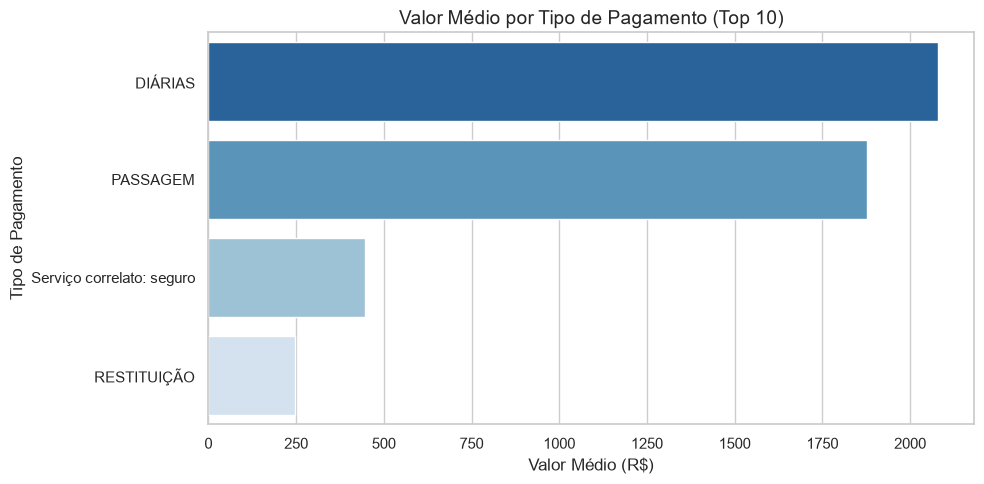

In [64]:
df_q4 = query_df("SELECT * FROM vw_gold_payment_types LIMIT 10;")

display(df_q4.style.format({"avg_amount": "R$ {:,.2f}"}).hide(axis="index"))

plt.figure(figsize=(10, 5))
sns.barplot(data=df_q4, x="avg_amount", y="payment_type", hue="payment_type", palette="Blues_r", legend=False)
plt.title("Valor Médio por Tipo de Pagamento (Top 10)", fontsize=14)
plt.xlabel("Valor Médio (R$)")
plt.ylabel("Tipo de Pagamento")
plt.tight_layout()
plt.show()

### 🧹 Função de Limpeza (Data Cleansing)
Como identificado na auditoria, o arquivo `2025_Pagamento.csv` possui falhas severas de codificação em sua origem (Mojibake). Os caracteres acentuados foram substituídos por caracteres de erro (`�`).

Em vez de simplesmente remover os acentos (o que corromperia palavras como "DIÁRIAS" para "DIARIAS"), foi implementada a função `clean_payment_type`. Ela atua como um mapeamento semântico: identifica as palavras-chave e restaura a string exata e correta (`DIÁRIAS`, `RESTITUIÇÃO`, `Serviço correlato: seguro`). 

Isso garante que os gráficos da camada Gold não apresentem erros de renderização (como o aviso *Glyph missing* do Matplotlib) e que as informações financeiras mantenham sua legibilidade e integridade originais para os tomadores de decisão.

## 5. Qual o meio de transporte mais usado nos trechos?
**Fonte:** `vw_gold_transport_modes`

transport_mode,usage_count
Veículo Oficial,386424
Aéreo,232666
Rodoviário,64970
Veículo Próprio,42846
Inválido,26659
Fluvial,8429
Ferroviário,874
Marítimo,481


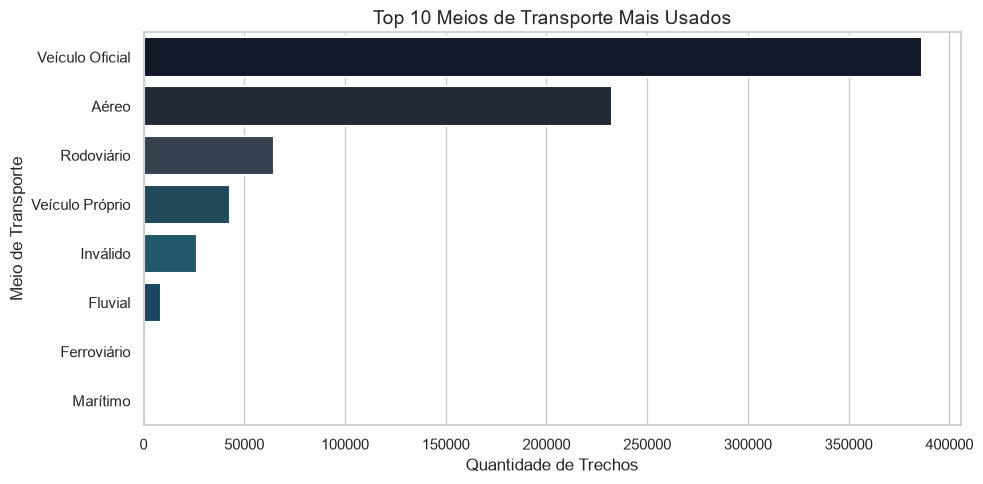

In [65]:
df_q5 = query_df("SELECT * FROM vw_gold_transport_modes LIMIT 10;")
display(df_q5.style.hide(axis="index"))

# Paleta customizada do Azul Escuro ao Ciano
paleta_q5 = [
    "#0F172A", # Slate Escuro
    "#1E293B", # Slate Médio
    "#334155", # Cinza Chumbo
    "#164E63", # Azul Petróleo Escuro
    "#155E75", # Azul Petróleo Médio
    "#0C4A6E", # Azul Ciano Escuro
    "#075985", # Azul Bebê Escuro
    "#1E3A8A"  # Azul Marinho
]

plt.figure(figsize=(10, 5))
# Adicionando edgecolor para o efeito 3D
sns.barplot(data=df_q5, x="usage_count", y="transport_mode", hue="transport_mode", 
            palette=paleta_q5, edgecolor="white", linewidth=1.5, legend=False)
plt.title("Top 10 Meios de Transporte Mais Usados", fontsize=14)
plt.xlabel("Quantidade de Trechos")
plt.ylabel("Meio de Transporte")
plt.tight_layout()
plt.show()

## 6. Qual a UF de destino que aparece em mais trechos?
**Fonte:** `vw_gold_destination_states`

destination_state,segment_count
São Paulo,82722
Distrito Federal,79962
Minas Gerais,50965
Rio de Janeiro,44197
Paraná,42603
Pará,40044
Rio Grande do Sul,38684
Mato Grosso do Sul,30516
Bahia,28375
Pernambuco,28372


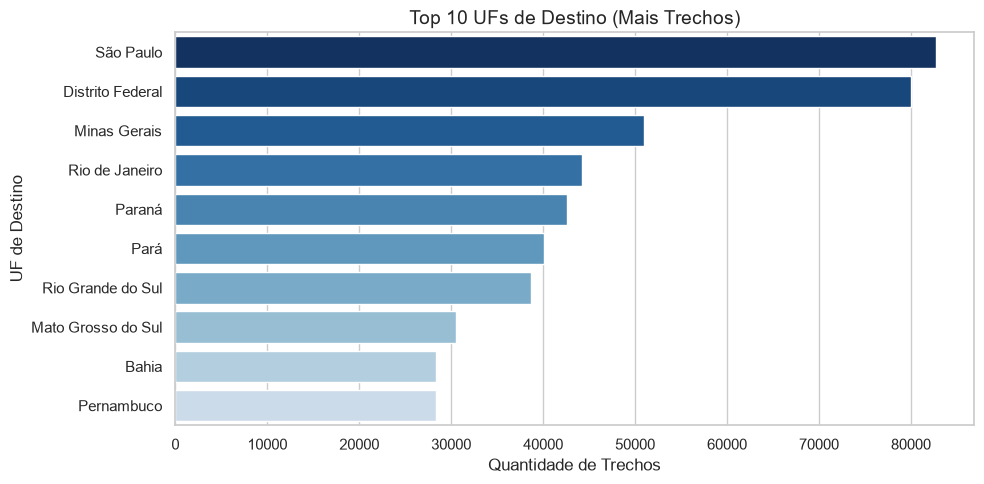

In [66]:
df_q6 = query_df("SELECT * FROM vw_gold_destination_states LIMIT 10;")
display(df_q6.style.hide(axis="index"))

cmap = sns.color_palette("Blues_r", as_cmap=True)
paleta_q6 = [cmap(x) for x in np.linspace(0.0, 0.75, 10)]

plt.figure(figsize=(10, 5))
sns.barplot(data=df_q6, x="segment_count", y="destination_state", hue="destination_state", palette=paleta_q6, legend=False)
plt.title("Top 10 UFs de Destino (Mais Trechos)", fontsize=14)
plt.xlabel("Quantidade de Trechos")
plt.ylabel("UF de Destino")
plt.tight_layout()
plt.show()

## 7. Qual o órgão que pagou mais no total?
**Fonte:** `vw_gold_top_payer_agencies` (usando JOIN entre `silver_trip` e `silver_payment`).

Órgão,Qtd. Viagens,Total Pago (R$)
Fundo Nacional de Segurança Pública,"24,116","R$ 278,481,047.89"
Sigiloso,"51,550","R$ 200,484,801.68"
Comando da Aeronáutica,"32,336","R$ 81,769,144.77"
Instituto Nacional do Seguro Social,"7,264","R$ 37,427,601.45"
Comando do Exército,"13,285","R$ 36,872,643.95"
Ministério da Gestão e da Inovação em Serviços Públicos - Unidades com vínculo direto,"9,428","R$ 35,541,760.71"
Instituto Brasileiro do Meio Ambiente e dos Recursos Naturais Renováveis,"8,809","R$ 31,589,853.15"
Ministério das Relações Exteriores - Unidades com vínculo direto,"1,927","R$ 25,605,376.38"
Receita Federal do Brasil,"10,063","R$ 23,811,027.00"
Ministério da Agricultura e Pecuária - Unidades com vínculo direto,"10,754","R$ 22,899,880.25"


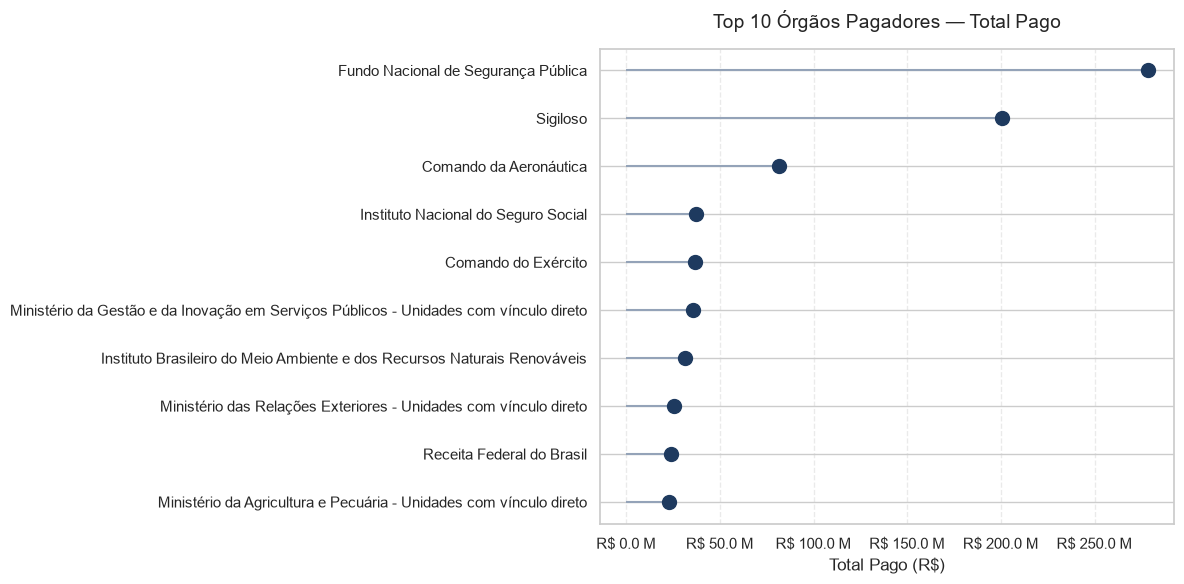

In [67]:
df_q7 = query_df("SELECT * FROM vw_gold_top_payer_agencies LIMIT 10;")
display(df_q7.rename(columns={
    "agency_name": "Órgão", 
    "trip_count": "Qtd. Viagens",
    "total_paid": "Total Pago (R$)"
}).style.format({
    "Qtd. Viagens": "{:,}",
    "Total Pago (R$)": "R$ {:,.2f}"
}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(12, 6))
y_pos = range(len(df_q7))

ax.hlines(y=y_pos, xmin=0, xmax=df_q7["total_paid"],
          color="#94a3b8", linewidth=1.5)
ax.plot(df_q7["total_paid"], y_pos, "o",
        markersize=10, color="#1e3a5f")

ax.set_yticks(y_pos)
ax.set_yticklabels(df_q7["agency_name"])
ax.invert_yaxis()
ax.set_xlabel("Total Pago (R$)", fontsize=12)
ax.set_title("Top 10 Órgãos Pagadores — Total Pago", fontsize=14, pad=15)
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"R$ {x/1e6:,.1f} M")
)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [68]:
# Busca os totais para a introdução
total_trips = query_df("SELECT COUNT(*) AS total FROM silver_trip;").iloc[0]["total"]
total_segments = query_df("SELECT COUNT(*) AS total FROM silver_segment;").iloc[0]["total"]
max_days = query_df("SELECT MAX(duration_days) AS max_d FROM silver_trip;").iloc[0]["max_d"]

# --- 1. Texto de Introdução ---
html_intro = f"""
<div style="font-size: 16px; line-height: 1.6; color: inherit; font-family: var(--jp-ui-font-family);">
    <h2 style="font-size: 22px; color: inherit; margin-bottom: 10px;">2. Principais Descobertas (Resumo Executivo)</h2>
    <p>A análise de mais de <strong>{total_trips:,}</strong> registros de viagens e <strong>{total_segments:,}</strong> trechos revela os seguintes insights sobre os gastos públicos:</p>
</div>
"""
display(HTML(html_intro))

# Puxando os dados das variáveis
top_agency = df_q1.iloc[0]["agency_name"]
top_cost = df_q1.iloc[0]["total_cost"]

top_dest = df_q2.iloc[0]["destination"]
dest_cost = df_q2.iloc[0]["avg_cost_per_trip"]

top_payment = df_q4.iloc[0]["payment_type"]
payment_avg = df_q4.iloc[0]["avg_amount"]
top_transport = df_q5.iloc[0]["transport_mode"]
top_payer = df_q7.iloc[0]["agency_name"]
top_paid = df_q7.iloc[0]["total_paid"]
top_trips = df_q7.iloc[0]["trip_count"]

# --- 2. Texto do Relatório ---
html_report = f"""
<div style="font-size: 16px; line-height: 1.6; color: inherit; font-family: var(--jp-ui-font-family);">
    
    <h3 style="font-size: 20px; color: inherit; margin-top: 20px; margin-bottom: 10px;">2.1 Concentração de Gastos</h3>
    <ul style="margin-top: 5px; margin-bottom: 15px; padding-left: 20px;">
        <li style="margin-bottom: 5px;"><strong>Órgão de Maior Custo:</strong> O órgão com o maior custo total é o <strong>{top_agency}</strong>, com uma despesa de <strong>R$ {top_cost:,.2f}</strong>.</li>
        <li style="margin-bottom: 5px;"><strong>Destino Mais Caro:</strong> O destino com o maior custo médio por viagem é <strong>{top_dest}</strong>, com <strong>R$ {dest_cost:,.2f}</strong>.</li>
    </ul>

    <h3 style="font-size: 20px; color: inherit; margin-top: 20px; margin-bottom: 10px;">2.2 Dinâmica Operacional</h3>
    <ul style="margin-top: 5px; margin-bottom: 15px; padding-left: 20px;">
        <li style="margin-bottom: 5px;"><strong>Pagamentos:</strong> O tipo de pagamento mais utilizado é <strong>{top_payment}</strong>, com valor médio de <strong>R$ {payment_avg:,.2f}</strong>.</li>
        <li style="margin-bottom: 5px;"><strong>Transporte:</strong> O meio de transporte mais comum nos trechos é <strong>{top_transport}</strong>.</li>
        <li style="margin-bottom: 5px;"><strong>Maior Pagador:</strong> O órgão que mais desembolsou foi o <strong>{top_payer}</strong>, pagando R$ {top_paid:,.2f} distribuídos em <strong>{top_trips:,} viagens</strong>.</li>
    </ul>

    <h3 style="font-size: 20px; color: inherit; margin-top: 20px; margin-bottom: 10px;">2.3 Qualidade dos Dados</h3>
    <ul style="margin-top: 5px; margin-bottom: 15px; padding-left: 20px;">
        <li style="margin-bottom: 5px;">A viagem mais longa registrada durou <strong>{max_days} dias</strong>. Devido à LGPD, o nome do viajante é oculto como <em>"Informações protegidas por sigilo"</em>.</li>
        <li style="margin-bottom: 5px;">Algumas viagens não possuíam dados financeiros (<code style="background: rgba(128,128,128,0.15); padding: 2px 4px; border-radius: 4px;">total_value = 0</code>). Essas foram filtradas dos cálculos para garantir a precisão analítica.</li>
        <li style="margin-bottom: 5px;">Na análise de meios de transporte, a categoria 'Inválido' representa cerca de 26 mil trechos onde o meio de transporte não foi reportado corretamente na origem. Isso evidencia a necessidade de melhorias na validação de formulários do sistema governamental.</li>
    </ul>

</div>
"""
display(HTML(html_report))

## Conclusões e Insights Finais

A construção deste pipeline de dados e a análise da camada Gold permitiram extrair as seguintes conclusões sobre as viagens a serviço do Governo Federal:

1. **Concentração de Gastos:** Existe uma forte concentração de despesas em órgãos específicos (como o Ministério da Justiça), o que indica a necessidade de políticas públicas de otimização de recursos e auditoria focada nessas pastas.

2. **Impacto dos Destinos:** Destinos com altos custos médios diários impactam significativamente o orçamento. A análise revela que o custo não está atrelado apenas à quantidade de dias, mas também ao valor das passagens (especialmente internacionais) e às diárias praticadas.

3. **Qualidade e Transparência dos Dados:** A auditoria identificou desafios reais no tratamento de dados governamentais, como a presença de caracteres corrompidos na origem, viagens com dados financeiros ausentes (`total_value = 0`) e restrições de privacidade (LGPD). O pipeline demonstrou-se robusto ao tratar e documentar essas anomalias.

4. **Visão Geral da Máquina Pública:** A análise dos meios de transporte e dos métodos de pagamento mais comuns comprova o alto volume de mobilidade dos servidores e reforça a importância da transparência pública para a fiscalização da sociedade.

## 📎 Anexo Técnico: Validação da Camada Gold e Diagnóstico

Para garantir a transparência e a corretude do pipeline, esta seção final apresenta as validações técnicas do banco de dados e um diagnóstico da qualidade dos dados brutos que foram processados ao longo do projeto.

### 1.1 Validação dos Objetos Criados
A consulta abaixo verifica a existência e a estruturação das tabelas físicas (`gold_*`) e das visões (`vw_gold_*`) criadas no PostgreSQL, comprovando a materialização da camada Gold.

In [ ]:
tables = query_df("""
    SELECT tablename AS name, 'table' AS type
    FROM pg_tables
    WHERE schemaname = 'public' AND tablename LIKE 'gold_%'
    UNION ALL
    SELECT viewname, 'view'
    FROM pg_views
    WHERE schemaname = 'public' AND viewname LIKE 'vw_gold_%'
    ORDER BY type, name;
""")
display(tables)

### 1.2 Diagnóstico de Integridade dos Dados
A consulta abaixo apresenta um raio-x da tabela principal de viagens (`silver_trip`), evidenciando a proporção de registros com custo zerado (dados ausentes na origem) e o maior tempo de duração registrado entre as viagens com custo válido.

In [ ]:
diag = query_df("""
    SELECT 
        COUNT(*) FILTER (WHERE total_value = 0) AS zero_cost_trips,
        COUNT(*) FILTER (WHERE total_value > 0) AS positive_cost_trips,
        COUNT(*) AS total,
        MAX(duration_days) FILTER (WHERE total_value > 0) AS max_days_positive
    FROM silver_trip;
""")
display(diag)